# MPAS Conservation / Model-Health Check

Tracks domain-integrated diagnostics over a forecast run to catch drift, blow-up, or
budget-closure problems early -- the kind of check a modeler runs on any new simulation
before trusting its output.

**Data**: SouthAmerica 240-48km variable-resolution tutorial run, 6-hourly `history.*.nc`
output from 2014-09-10 00Z to 2014-09-15 00Z (21 time steps).

**Diagnostics**: domain-total dry-air mass, the moisture budget (precipitable water
change vs. evaporation minus precipitation), domain-mean T2m/surface pressure, and
domain-total kinetic energy.

Ming Ge Nov. 2026

In [1]:
import glob

import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.tri as tri
import cartopy.crs as ccrs
import cartopy.feature as cfeature

### Load mesh geometry (cell area, layer thickness) -- time-invariant, read once

In [2]:
data_dir = '/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/'
history_files = sorted(glob.glob(data_dir + 'history.2014-09-*.nc'))
print(f'{len(history_files)} history files found')

# zgrid (layer-interface height) and areaCell don't change in time, so read them once
with xr.open_dataset(history_files[0]) as ds0:
    areaCell = ds0['areaCell'].values           # m^2, per cell
    zgrid = ds0['zgrid'].values                 # m, layer interfaces (nCells, nVertLevelsP1)
    lonCell = np.degrees(ds0['lonCell'].values)
    latCell = np.degrees(ds0['latCell'].values)

# layer thickness between interfaces -> (nCells, nVertLevels), used to column-integrate
dz = np.diff(zgrid, axis=1)

lonCell = ((lonCell + 180) % 360) - 180  # wrap to [-180, 180] for plotting

21 history files found


### Domain context: mesh resolution

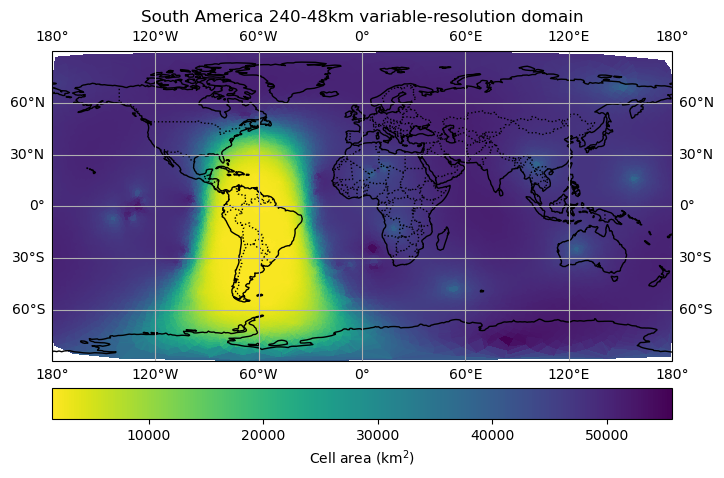

In [3]:
triang = tri.Triangulation(lonCell, latCell)

fig, ax = plt.subplots(figsize=(8, 7), subplot_kw={'projection': ccrs.PlateCarree()})
mm = ax.tripcolor(triang, areaCell / 1e6, cmap='viridis_r')  # km^2, shows the variable-resolution mesh
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.gridlines(draw_labels=True)
plt.colorbar(mm, orientation='horizontal', pad=0.05, label='Cell area (km$^2$)')
ax.set_title('South America 240-48km variable-resolution domain');

### Loop over history files, computing area- and mass-weighted domain integrals at each time step

In [4]:
records = []

for f in history_files:
    with xr.open_dataset(f) as ds:
        t = pd.to_datetime(ds['xtime'].values[0].decode().strip()[:19], format='%Y-%m-%d_%H:%M:%S')

        rho = ds['rho'].isel(Time=0).values                              # kg m^-3, dry-air density
        qcond = (ds['qc'] + ds['qr'] + ds['qi'] + ds['qs'] + ds['qg']).isel(Time=0).values
        ke = ds['ke'].isel(Time=0).values                                # m^2 s^-2, per unit mass
        precipw = ds['precipw'].isel(Time=0).values                      # kg m^-2, column water-vapor path
        rain_total = (ds['rainc'] + ds['rainnc']).isel(Time=0).values    # mm == kg m^-2, accumulated since run start
        qfx = ds['qfx'].isel(Time=0).values                              # kg m^-2 s^-1, surface evaporation flux
        t2m = ds['t2m'].isel(Time=0).values
        psfc = ds['surface_pressure'].isel(Time=0).values

    # column-integrate each cell over the vertical (sum rho*dz etc.), then area-weight and
    # sum over the whole domain to get a single domain-total number per time step
    dry_air_mass = ((rho * dz).sum(axis=1) * areaCell).sum()               # kg
    condensate_mass = ((qcond * rho * dz).sum(axis=1) * areaCell).sum()    # kg
    kinetic_energy = ((ke * rho * dz).sum(axis=1) * areaCell).sum()        # J
    precipitable_water = (precipw * areaCell).sum()                       # kg
    accumulated_precip = (rain_total * areaCell).sum()                    # kg
    evap_flux_rate = (qfx * areaCell).sum()                               # kg s^-1, instantaneous
    mean_t2m = (t2m * areaCell).sum() / areaCell.sum()
    mean_psfc = (psfc * areaCell).sum() / areaCell.sum()

    records.append(dict(time=t, dry_air_mass=dry_air_mass, condensate_mass=condensate_mass,
                         kinetic_energy=kinetic_energy, precipitable_water=precipitable_water,
                         accumulated_precip=accumulated_precip, evap_flux_rate=evap_flux_rate,
                         mean_t2m=mean_t2m, mean_psfc=mean_psfc))

df = pd.DataFrame(records).set_index('time').sort_index()
df

,dry_air_mass,condensate_mass,kinetic_energy,precipitable_water,accumulated_precip,evap_flux_rate,mean_t2m,mean_psfc
time,,,,,,,,
2014-09-10 00:00:00,5.053394e+18,0.000000e+00,8.350491e+20,1.290986e+16,0.000000e+00,0.000000e+00,288.527496,98543.726562
2014-09-10 06:00:00,5.053394e+18,3.808105e+13,8.320445e+20,1.292548e+16,1.997869e+14,1.778644e+10,288.152679,98545.382812
2014-09-10 12:00:00,5.053394e+18,4.437603e+13,8.262853e+20,1.298211e+16,5.106902e+14,1.755041e+10,288.452057,98545.406250
2014-09-10 18:00:00,5.053394e+18,4.745843e+13,8.218172e+20,1.298938e+16,8.711800e+14,1.722526e+10,287.957672,98545.148438
2014-09-11 00:00:00,5.053394e+18,4.794089e+13,8.179280e+20,1.296806e+16,1.226975e+15,1.499543e+10,287.350555,98544.117188
2014-09-11 06:00:00,5.053394e+18,5.080750e+13,8.108851e+20,1.295333e+16,1.568655e+15,1.646238e+10,287.694214,98542.875000
2014-09-11 12:00:00,5.053394e+18,5.058860e+13,8.051206e+20,1.294931e+16,1.924678e+15,1.664506e+10,288.159546,98542.117188
2014-09-11 18:00:00,5.053395e+18,5.119880e+13,7.994276e+20,1.294505e+16,2.280482e+15,1.639673e+10,287.730865,98541.546875
2014-09-12 00:00:00,5.053394e+18,4.965804e+13,7.926584e+20,1.292958e+16,2.619921e+15,1.462699e+10,287.157379,98540.453125


### Dry-air mass (limited-area domain, so some lateral-boundary drift is expected)

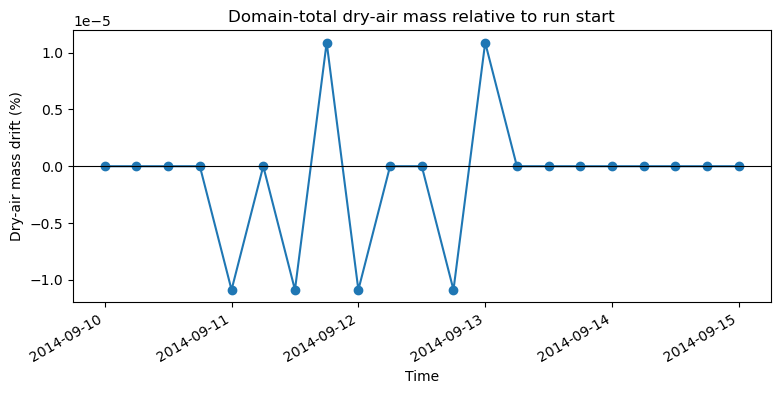

In [5]:
rel_drift = (df['dry_air_mass'] - df['dry_air_mass'].iloc[0]) / df['dry_air_mass'].iloc[0] * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df.index, rel_drift, marker='o')
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Dry-air mass drift (%)')
ax.set_xlabel('Time')
ax.set_title('Domain-total dry-air mass relative to run start')
fig.autofmt_xdate()

# This is a limited-area (LAM) domain, so mass is not strictly conserved -- lateral
# boundary inflow/outflow changes domain-total mass. A large or steadily growing
# drift unrelated to synoptic boundary forcing is still worth investigating (e.g. a
# numerical mass-conservation bug), but small fluctuations tracking the boundary
# conditions are expected and not a bug.

### Moisture budget closure

,dPW/dt (observed),Evap - Precip (expected),residual (lateral transport)
time,,,
2014-09-10 00:00:00,NaN,NaN,NaN
2014-09-10 06:00:00,1.561757e+13,-7.693326e+12,2.331090e+13
2014-09-10 12:00:00,5.663666e+13,7.073471e+13,-1.409805e+13
2014-09-10 18:00:00,7.268158e+12,1.508734e+13,-7.819183e+12
2014-09-11 00:00:00,-2.132344e+13,-7.811454e+12,-1.351198e+13
2014-09-11 06:00:00,-1.473389e+13,-1.936334e+12,-1.279755e+13
2014-09-11 12:00:00,-4.017942e+12,1.538161e+12,-5.556103e+12
2014-09-11 18:00:00,-4.258460e+12,1.047081e+12,-5.305541e+12
2014-09-12 00:00:00,-1.547047e+13,-4.382869e+12,-1.108760e+13


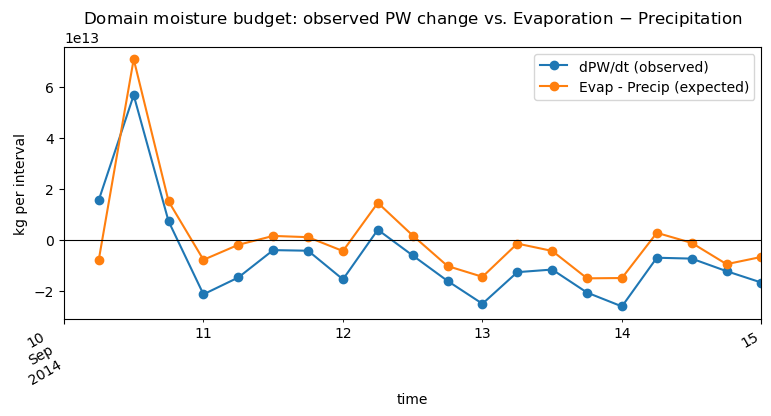

In [6]:
dt_seconds = df.index.to_series().diff().dt.total_seconds()

# trapezoidal-integrated evaporation, and interval precip, between consecutive outputs
evap_interval = 0.5 * (df['evap_flux_rate'] + df['evap_flux_rate'].shift(1)) * dt_seconds
precip_interval = df['accumulated_precip'].diff()
pw_change = df['precipitable_water'].diff()

budget = pd.DataFrame({
    'dPW/dt (observed)': pw_change,
    'Evap - Precip (expected)': evap_interval - precip_interval,
})
budget['residual (lateral transport)'] = budget['dPW/dt (observed)'] - budget['Evap - Precip (expected)']

fig, ax = plt.subplots(figsize=(9, 4))
budget[['dPW/dt (observed)', 'Evap - Precip (expected)']].plot(ax=ax, marker='o')
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('kg per interval')
ax.set_title('Domain moisture budget: observed PW change vs. Evaporation $-$ Precipitation')
fig.autofmt_xdate()

# For a global/periodic domain these two lines would overlay almost exactly (moisture
# conservation). For this limited-area domain the gap is the net moisture flux through
# the lateral boundaries -- not a bug, but worth tracking if it grows unexpectedly large.
budget

### Domain-mean surface fields (basic run-health check)

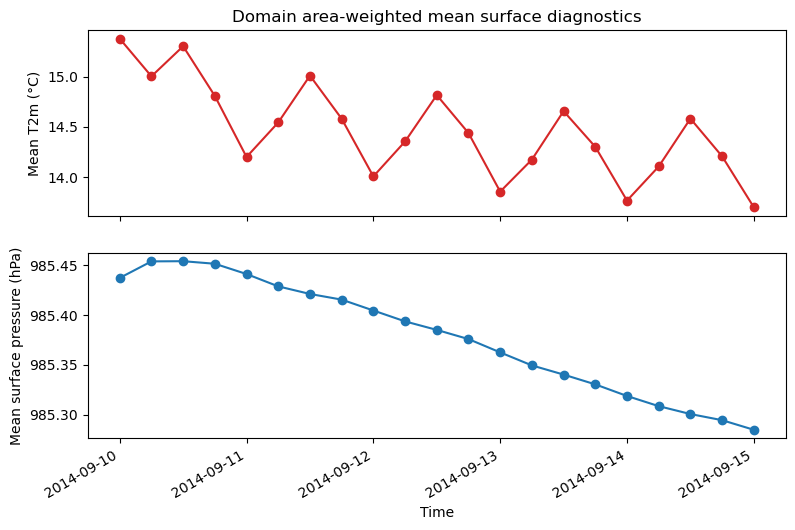

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(df.index, df['mean_t2m'] - 273.15, marker='o', color='tab:red')
axes[0].set_ylabel('Mean T2m (°C)')
axes[0].set_title('Domain area-weighted mean surface diagnostics')

axes[1].plot(df.index, df['mean_psfc'] / 100, marker='o', color='tab:blue')
axes[1].set_ylabel('Mean surface pressure (hPa)')
axes[1].set_xlabel('Time')

fig.autofmt_xdate()

### Domain-total kinetic energy

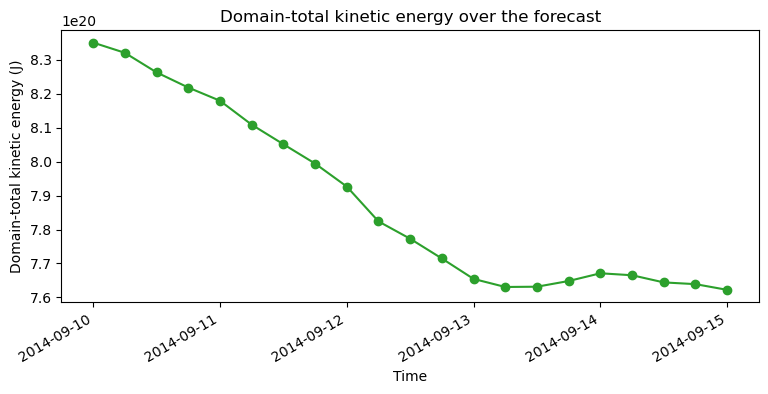

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df.index, df['kinetic_energy'], marker='o', color='tab:green')
ax.set_ylabel('Domain-total kinetic energy (J)')
ax.set_xlabel('Time')
ax.set_title('Domain-total kinetic energy over the forecast')
fig.autofmt_xdate()

# A steadily growing KE with no corresponding synoptic driver can indicate spurious
# numerical energy production (e.g. under-damped gravity waves); a steady decline can
# indicate excessive numerical diffusion.